# 05 — Evaluate adv-NO fix-window rollout

**Active:** `adv_no_uv_18_21_dt360_vgg_warm10_adv60` evaluated on `data/sample_17_sep_dec_smallfixwin_uv_dt360` (2017 Sep–Dec holdout, last 4 months, u+v, `DT=360` h, N≈122).

3-step autoregressive rollout at **+15d / +30d / +45d**. GT at +15d from export; +30d / +45d loaded from Zarr (same fix window).

Speed metrics reported for **center 4×4** and **full valid field** (persistence vs model RMSE).

`# Old:` `sample_23_jan_jun_*`; full-year `sample_17_*` / `sample_23_*`; `adv_no_uv_13_22_*` on `sample_22_*` (commented in config cell).

At inference only the U-Net is used (discriminator discarded).

In [ ]:
import json
import os
import sys
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from gUnet import Unet2D

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.dataloaders.guiana_margem_tensor import GuianaDataloader
from src.data.useful_transforms import RotatedFixedCrop

# --- adv-NO run + eval data (switch RUN_NAME here, then re-run cell) ---
RUN_NAME = "adv_no_uv_18_21_dt360_vgg_warm10_adv60"  # trained 2018–2021
# RUN_NAME = "adv_no_uv_13_22_dt360_vgg_warm10_adv60"  # trained 2013–2022 (old)
# RUN_NAME = "adv_no_uv_23_dt360_vgg_warm10_adv60"  # trained 2023 only (old)
RUN_DIR = Path("Models/adv_no") / RUN_NAME
MODEL_PATH = RUN_DIR / "best_model.pth"
STATS_PATH = RUN_DIR / "norm_stats.pt"

DT = 360  # 15-day / 360 h between frames (3 cond + 1 pred export)
# DT = 96  # 4-day steps (old: 60-frame export)
DT_STEP_DAYS = DT // 24

# --- eval data (switch DATA_PREFIX; keep RUN_NAME aligned with model) ---
DATA_PREFIX = "data/sample_17_sep_dec_smallfixwin_uv_dt360"  # 2017 Sep–Dec (last 4 months) holdout eval
EVAL_TAG = "2017-sep-dec"  # used in saved PNG filenames

# --- other eval datasets (prefix must match 01_export_fix_window_data output) ---
# DATA_PREFIX = "data/sample_17_smallfixwin_uv_dt360"  # 2017 full year
# EVAL_TAG = "2017"
# DATA_PREFIX = "data/sample_23_jan_jun_smallfixwin_uv_dt360"  # 2023 Jan–Jun
# EVAL_TAG = "2023-jan-jun"
# DATA_PREFIX = "data/sample_22_smallfixwin_uv_dt360"  # 2022 holdout
# EVAL_TAG = "2022"
# DATA_PREFIX = "data/sample_23_smallfixwin_uv_dt360"  # 2023 full year
# EVAL_TAG = "2023"
# DATA_PREFIX = "data/sample_22_23_smallfixwin_uv_dt360"  # 2022–2023 holdout
# EVAL_TAG = "22-23"
# DATA_PREFIX = "data/sample_13_22_smallfixwin_uv_dt360"  # train-period 2013–2022
# EVAL_TAG = "13-22"
# DATA_PREFIX = "data/sample_20_21_smallfixwin_dt96"  # old dt96 (no _uv suffix)
# DATA_PREFIX = "data/sample_20_21_fixwin_dt96"  # old large-window dt96 (no _uv)
# RUN_NAME = "adv_no_uv_16_19_dt96_gauss_sigma32"  # old gauss-center run

_required = Path(f"{DATA_PREFIX}_sims.npy")
if not _required.exists():
    raise FileNotFoundError(
        f"Missing eval export: {_required}\n"
        "Run 01_export_fix_window_data.ipynb or check DATA_PREFIX."
    )

iD = 2
CHANNEL_NAMES = ["U", "V"]

SPEED_PATCH_SIZE = 4  # center patch for plots + center metrics
EVAL_HORIZONS = (DT_STEP_DAYS, 2 * DT_STEP_DAYS, 3 * DT_STEP_DAYS)
H1, H2, H3 = EVAL_HORIZONS
FORECAST_TITLES = tuple(f"t[n+{d}d]" for d in EVAL_HORIZONS)

EXPORT_CONFIG_PATH = Path(f"{DATA_PREFIX}_export_config.json")
WINDOW_META = np.load(f"{DATA_PREFIX}_window.npy")

# ----------------------------
# Load test data
# ----------------------------
def load_test_data(
    sims_path: str = f"{DATA_PREFIX}_sims.npy",
    mask_path: str = f"{DATA_PREFIX}_mask.npy",
    day_path: str = f"{DATA_PREFIX}_day.npy",
    hour_path: str = f"{DATA_PREFIX}_hour.npy",
    latlon_path: str = f"{DATA_PREFIX}_latlon.npy",
    indices_path: str = f"{DATA_PREFIX}_indices.npy",
    stats_path: str = str(STATS_PATH),
    test_split: float = 1.0,
    seed: int = 42,
):
    sims = torch.from_numpy(np.load(sims_path))
    mask = torch.from_numpy(np.load(mask_path))
    day = torch.from_numpy(np.load(day_path))
    hour = torch.from_numpy(np.load(hour_path))
    latlon = torch.from_numpy(np.load(latlon_path))
    export_indices = np.load(indices_path)

    valid = ~(mask > 0).any(dim=(1, 2))
    sims = sims[valid]
    mask = mask[valid]
    day = day[valid]
    hour = hour[valid]
    latlon = latlon[valid]
    export_indices = export_indices[valid]

    n = len(sims)
    rng = np.random.default_rng(seed)
    test_idx = rng.permutation(n)[: int(n * test_split)]

    stats = torch.load(stats_path, map_location="cpu")
    mean = stats["mean"]
    std = stats["std"]
    mean_x = mean.repeat(1, 3, 1, 1)
    std_x = std.repeat(1, 3, 1, 1)

    return {
        "sims": sims[test_idx],
        "mask": mask[test_idx],
        "day": day[test_idx] / 365.0,
        "hour": hour[test_idx] / 365.0,
        "latlon": latlon[test_idx],
        "mean": mean_x,
        "std": std_x,
        "n_frames": int(sims.shape[1]),
        "export_indices": export_indices[test_idx],
    }


def _build_zarr_loader():
    cfg = json.loads(EXPORT_CONFIG_PATH.read_text())
    top, left, h, w, angle = WINDOW_META
    crop = RotatedFixedCrop(
        size=(int(h), int(w)),
        top=int(top),
        left=int(left),
        angle_deg=float(angle),
    )
    return GuianaDataloader(
        path=cfg["zarr_path"],
        dt=DT,
        conditioning_steps=3,
        forecast_steps=1,
        transform=crop,
    )


def _load_cropped_uv_at(zarr_ds, timestamp) -> torch.Tensor:
    """Load cropped u,v at one Zarr time. Returns [2, H, W]."""
    t = pd.Timestamp(timestamp)
    fields = zarr_ds.load_uvssh_frame(t).astype(np.float32, copy=False)  # [3, H, W] u,v,ssh
    fields = np.nan_to_num(fields, nan=0.0)
    h, w = fields.shape[-2:]
    mask_ch = (~np.isfinite(fields[:1])).astype(np.float32)
    bat = np.ones((1, h, w), dtype=np.float32)
    lat, lon = zarr_ds._latlon_grid(h, w)
    bundle = torch.cat(
        [
            torch.tensor(mask_ch, dtype=torch.float32).unsqueeze(0),
            torch.tensor(fields, dtype=torch.float32).unsqueeze(0),
            torch.tensor(bat, dtype=torch.float32).unsqueeze(0),
            torch.tensor(lat, dtype=torch.float32).unsqueeze(0).unsqueeze(0),
            torch.tensor(lon, dtype=torch.float32).unsqueeze(0).unsqueeze(0),
        ],
        dim=1,
    )
    if zarr_ds.transform is not None:
        bundle = zarr_ds.transform(bundle)
        if not torch.is_tensor(bundle):
            bundle = torch.tensor(bundle, dtype=torch.float32)
    _, data, _, _, _ = torch.split(bundle, [1, 3, 1, 1, 1], dim=1)
    return data[0, :2].clone()


def load_gt_horizons_from_zarr(export_indices: np.ndarray, horizons_days: tuple[int, ...]) -> dict[int, torch.Tensor]:
    """Load cropped GT u,v at anchor + each horizon (days). Returns {days: [N,2,H,W]}."""
    zarr_ds = _build_zarr_loader()
    out = {d: [] for d in horizons_days}
    missing = {d: 0 for d in horizons_days}
    for ds_idx in export_indices:
        times = zarr_ds.sample_times(int(ds_idx))
        anchor = pd.Timestamp(times[2])
        for d in horizons_days:
            t = anchor + pd.Timedelta(days=d)
            if t not in zarr_ds.time_to_idx:
                missing[d] += 1
                out[d].append(torch.zeros(iD, CROP_HEIGHT, CROP_WIDTH))
                continue
            out[d].append(_load_cropped_uv_at(zarr_ds, t))
    for d in horizons_days:
        if missing[d]:
            print(f"Warning: {missing[d]} samples missing Zarr GT at +{d}d")
        out[d] = torch.stack(out[d], dim=0)
    return out


# ----------------------------
# Center-patch metrics (4×4 at crop center)
# ----------------------------
def _center_slices(h: int, w: int, patch: int) -> tuple[slice, slice]:
    cy, cx = h // 2, w // 2
    half = patch // 2
    if patch % 2 == 0:
        return slice(cy - half, cy + half), slice(cx - half, cx + half)
    return slice(cy - half, cy + half + 1), slice(cx - half, cx + half + 1)


def _crop_metric_region(field: np.ndarray, mask: np.ndarray, patch_size: int | None):
    if patch_size is None:
        return field, mask
    sy, sx = _center_slices(field.shape[-2], field.shape[-1], patch_size)
    return field[..., sy, sx], mask[..., sy, sx]


def patch_rmse_2d(a: np.ndarray, b: np.ndarray, mask: np.ndarray, patch_size: int | None = None) -> float:
    patch_size = SPEED_PATCH_SIZE if patch_size is None else patch_size
    a, mask = _crop_metric_region(a, mask, patch_size)
    b, _ = _crop_metric_region(b, mask, patch_size)
    valid = mask == 0
    if not np.any(valid):
        return float("nan")
    return float(np.sqrt(np.mean((a[valid] - b[valid]) ** 2)))


# ----------------------------
# Inference
# ----------------------------
def run_inference(
    model: torch.nn.Module,
    test_data: dict,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
    batch_size: int = 16,
    iD: int = 2,
    dt_step_days: float = DT_STEP_DAYS,
):
    model = model.to(device).eval()

    sims = test_data["sims"][:, :, :iD, :, :]
    day = test_data["day"]
    hour = test_data["hour"]
    mean = test_data["mean"]
    std = test_data["std"]
    n_t = int(sims.shape[1])

    y_mean = mean[:, :iD, :, :]
    y_std = std[:, :iD, :, :]

    use_compact = n_t <= 4
    if use_compact:
        x1 = torch.cat([sims[:, 0], sims[:, 1], sims[:, 2]], dim=1).float()
    else:
        x1 = torch.cat([sims[:, 1], sims[:, 2], sims[:, 3]], dim=1).float()
    x1 = (x1 - mean) / (std + 1e-8)

    dataset = torch.utils.data.TensorDataset(x1, day, hour)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    preds1, preds2, preds3 = [], [], []

    with torch.no_grad():
        for x_batch, d_batch, h_batch in dataloader:
            x_batch = x_batch.to(device)
            d_batch = d_batch.to(device)
            h_batch = h_batch.to(device)

            pred1 = model(x_batch, d_batch + h_batch / 365.0)
            pred1 = pred1 + x_batch[:, -iD:]

            x_batch2 = torch.cat([x_batch[:, iD : 2 * iD], x_batch[:, 2 * iD : 3 * iD], pred1], dim=1)
            pred2 = model(x_batch2, d_batch + h_batch / 365.0 + dt_step_days / 365.0)
            pred2 = pred2 + x_batch2[:, -iD:]

            x_batch3 = torch.cat([x_batch[:, 2 * iD : 3 * iD], x_batch2[:, -iD:], pred2], dim=1)
            pred3 = model(x_batch3, d_batch + h_batch / 365.0 + 2 * dt_step_days / 365.0)
            pred3 = pred3 + pred2

            preds1.append(pred1.cpu())
            preds2.append(pred2.cpu())
            preds3.append(pred3.cpu())

    preds1 = torch.cat(preds1, dim=0)
    preds2 = torch.cat(preds2, dim=0)
    preds3 = torch.cat(preds3, dim=0)

    preds_denorm1 = preds1 * (y_std + 1e-8) + y_mean
    preds_denorm2 = preds2 * (y_std + 1e-8) + y_mean
    preds_denorm3 = preds3 * (y_std + 1e-8) + y_mean

    if use_compact:
        s1, s2, s3, s4 = sims[:, 0], sims[:, 1], sims[:, 2], sims[:, 3]
        gt_extra = load_gt_horizons_from_zarr(test_data["export_indices"], (H2, H3))
        s5, s6 = gt_extra[H2], gt_extra[H3]
    else:
        s1, s2, s3 = sims[:, 1], sims[:, 2], sims[:, 3]
        s4, s5, s6 = sims[:, 4], sims[:, 5], sims[:, 6]

    return s1, s2, s3, s4, s5, s6, preds_denorm1, preds_denorm2, preds_denorm3


def apply_mask(field: np.ndarray, mask: np.ndarray) -> np.ndarray:
    out = field.copy()
    out[mask == 1] = np.nan
    return out


def isotropic_spectrum(field):
    H, W = field.shape
    fft = np.fft.rfft2(field)
    power = np.abs(fft) ** 2
    ky = np.fft.fftfreq(H)
    kx = np.fft.rfftfreq(W)
    ky, kx = np.meshgrid(ky, kx, indexing="ij")
    k_mag = np.sqrt(kx ** 2 + ky ** 2)
    k_flat = k_mag.flatten()
    p_flat = power.flatten()
    k_max = min(H, W) // 2
    spectrum = np.zeros(k_max)
    for i in range(k_max - 1):
        mask_k = (k_flat >= i / k_max) & (k_flat < (i + 1) / k_max)
        if np.any(mask_k):
            spectrum[i] = p_flat[mask_k].mean()
    return np.arange(k_max), spectrum


def plot_sample(
    s1, s2, s3, s4, s5, s6, p1, p2, p3,
    test_data: dict,
    sample_idx: int = 0,
    save_path: str | None = None,
):
    s1 = s1[sample_idx].numpy()
    s2 = s2[sample_idx].numpy()
    s3 = s3[sample_idx].numpy()
    s4 = s4[sample_idx].numpy()
    s5 = s5[sample_idx].numpy()
    s6 = s6[sample_idx].numpy()
    p1 = p1[sample_idx].numpy()
    p2 = p2[sample_idx].numpy()
    p3 = p3[sample_idx].numpy()
    mask = test_data["mask"][sample_idx].numpy()
    day = test_data["day"][sample_idx].item()
    hour = test_data["hour"][sample_idx].item()
    lat, lon = test_data["latlon"][sample_idx].tolist()
    n_channels = p1.shape[0]

    S3 = (s3[0] ** 2 + s3[1] ** 2) ** 0.5
    gt_speeds = [
        (s4[0] ** 2 + s4[1] ** 2) ** 0.5,
        (s5[0] ** 2 + s5[1] ** 2) ** 0.5,
        (s6[0] ** 2 + s6[1] ** 2) ** 0.5,
    ]
    pred_speeds = [
        (p1[0] ** 2 + p1[1] ** 2) ** 0.5,
        (p2[0] ** 2 + p2[1] ** 2) ** 0.5,
        (p3[0] ** 2 + p3[1] ** 2) ** 0.5,
    ]
    errs = [
        (np.sqrt(np.nanmean((gt_speeds[i] - S3) ** 2)), np.sqrt(np.nanmean((pred_speeds[i] - gt_speeds[i]) ** 2)))
        for i in range(3)
    ]

    if save_path is not None:
        fig = plt.figure(figsize=(6 * 3, 2 * n_channels * 3))
        fig.suptitle(
            f"Sample {sample_idx} | Day {int(day * 365):3d}, Hour {int(hour * 365 * 24):2d}h | "
            f"Lat {lat:.2f}, Lon {lon:.2f} — adv-NO rollout +{H1}/{H2}/{H3}d",
            fontsize=13,
            fontweight="bold",
        )
        gs = gridspec.GridSpec(n_channels * 2, 6, figure=fig, wspace=0.35, hspace=0.4)
        gt_fields = [s4, s5, s6]
        pred_fields = [p1, p2, p3]
        titles = FORECAST_TITLES

        for ch in range(n_channels):
            ss = [apply_mask(s1[ch], mask), apply_mask(s2[ch], mask), apply_mask(s3[ch], mask)]
            for col, field, title in zip(range(3), ss, ["t[n-2]", "t[n-1]", "t[n]"]):
                ax = fig.add_subplot(gs[2 * ch, col])
                vmin = np.nanmin(ss + [apply_mask(g[ch], mask) for g in gt_fields] + [apply_mask(p[ch], mask) for p in pred_fields])
                vmax = np.nanmax(ss + [apply_mask(g[ch], mask) for g in gt_fields] + [apply_mask(p[ch], mask) for p in pred_fields])
                im = ax.imshow(field, vmin=vmin, vmax=vmax, cmap="viridis")
                ax.set_title(f"{CHANNEL_NAMES[ch]} — {title}")
                ax.axis("off")
                plt.colorbar(im, ax=ax, fraction=0.046)

            for j, (gf, pf, title) in enumerate(zip(gt_fields, pred_fields, titles)):
                col = 3 + j
                g = apply_mask(gf[ch], mask)
                p = apply_mask(pf[ch], mask)
                vmin = np.nanmin([g, p])
                vmax = np.nanmax([g, p])
                ax = fig.add_subplot(gs[2 * ch, col])
                im = ax.imshow(g, vmin=vmin, vmax=vmax, cmap="viridis")
                ax.set_title(f"GT {title}")
                ax.axis("off")
                plt.colorbar(im, ax=ax, fraction=0.046)

            for j, (pf, title, (pe, ue)) in enumerate(zip(pred_fields, titles, errs)):
                ax = fig.add_subplot(gs[2 * ch + 1, 3 + j])
                p = apply_mask(pf[ch], mask)
                vmin = np.nanmin(p)
                vmax = np.nanmax(p)
                im = ax.imshow(p, vmin=vmin, vmax=vmax, cmap="magma")
                ax.set_title(f"Pred {title}\nP {pe:.3e} | M {ue:.3e}", fontsize=8)
                ax.axis("off")
                plt.colorbar(im, ax=ax, fraction=0.046)

        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.close(fig)
        print(f"Saved to {save_path}")

    return errs[0][0], errs[0][1], errs[1][0], errs[1][1], errs[2][0], errs[2][1]


# ----------------------------
# Usage
# ----------------------------
_sims_shape = np.load(f"{DATA_PREFIX}_sims.npy", mmap_mode="r").shape
CROP_HEIGHT, CROP_WIDTH = _sims_shape[-2], _sims_shape[-1]
N_FRAMES = int(_sims_shape[1])
USE_ZARR_GT = N_FRAMES <= 4

print(f"Run: {RUN_NAME}")
print(f"Model: {MODEL_PATH}")
print(f"Dataset: {DATA_PREFIX}")
print(f"Crop size: {CROP_HEIGHT} x {CROP_WIDTH} | iD={iD} | frames={N_FRAMES}")
print(f"Rollout horizons: +{H1}d, +{H2}d, +{H3}d (DT={DT}h)")
if USE_ZARR_GT:
    print(f"GT +{H2}d/+{H3}d: loaded from Zarr via export indices")
print(f"Metrics: center {SPEED_PATCH_SIZE}x{SPEED_PATCH_SIZE} and full valid field")

Par = {
    "lb": 3,
    "nf": iD,
    "nx": CROP_HEIGHT,
    "ny": CROP_WIDTH,
    "inp_shift": 0.0,
    "inp_scale": 1.0,
    "out_shift": 0.0,
    "out_scale": 1.0,
    "t_shift": 0.0,
    "t_scale": 1.0,
}
model = Unet2D(dim=32, Par=Par, dim_mults=(1, 2, 4, 8), channels=Par["lb"] * Par["nf"])
model.load_state_dict(torch.load(MODEL_PATH, map_location="cpu", weights_only=True))

test_data = load_test_data()
s1, s2, s3, s4, s5, s6, p1, p2, p3 = run_inference(model, test_data, iD=iD)
print("=>", s1.shape, p1.shape, s5.shape)

PNG_DIR = "PNG"
os.makedirs(PNG_DIR, exist_ok=True)
PLOT_INDICES = [0, 1, 2, 45, 32]

for i in PLOT_INDICES:
    if i >= s1.shape[0]:
        continue
    plot_sample(
        s1, s2, s3, s4, s5, s6, p1, p2, p3,
        test_data,
        sample_idx=i,
        save_path=os.path.join(PNG_DIR, f"adv_no_{RUN_NAME}_sample_{i}.png"),
    )

SyntaxError: unterminated f-string literal (detected at line 56) (2668927727.py, line 56)

## Velocity magnitude & persistence error (+15d / +30d / +45d)

Run the inference cell above first (loads +30/+45d GT from Zarr when export has 4 frames).

- **Speed** $|\mathbf{u}| = \sqrt{u^2 + v^2}$
- **Persistence**: RMSE vs anchor speed $t[n]$
- **Model**: RMSE vs GT speed at each horizon

Reported for **center 4×4** and **full valid field**.


In [ ]:
def speed_magnitude(states) -> np.ndarray:
    arr = states.numpy() if torch.is_tensor(states) else np.asarray(states)
    return np.sqrt(arr[:, 0] ** 2 + arr[:, 1] ** 2)


def masked_rmse(field_a: np.ndarray, field_b: np.ndarray, mask: np.ndarray, patch_size: int | None = None) -> float:
    field_a, mask = _crop_metric_region(field_a, mask, patch_size)
    field_b, _ = _crop_metric_region(field_b, mask, patch_size)
    diff2 = (field_b - field_a) ** 2
    valid = mask == 0
    if not np.any(valid):
        return float("nan")
    return float(np.sqrt(diff2[valid].mean()))


def rollout_speed_metrics(
    gt_now,
    gt_h1,
    gt_h2,
    gt_h3,
    pred_h1,
    pred_h2,
    pred_h3,
    mask,
    horizons,
    patch_size: int | None = None,
):
    speed_now = speed_magnitude(gt_now)
    gt_speeds = [speed_magnitude(gt_h1), speed_magnitude(gt_h2), speed_magnitude(gt_h3)]
    pred_speeds = [speed_magnitude(pred_h1), speed_magnitude(pred_h2), speed_magnitude(pred_h3)]
    mask_np = mask.numpy() if torch.is_tensor(mask) else np.asarray(mask)

    rows = []
    for days, gt_spd, pred_spd in zip(horizons, gt_speeds, pred_speeds):
        persist = masked_rmse(speed_now, gt_spd, mask_np, patch_size)
        model = masked_rmse(pred_spd, gt_spd, mask_np, patch_size)
        skill = 1.0 - model / persist if persist > 0 else float("nan")
        rows.append(
            {
                "horizon_days": days,
                "persistence_rmse": persist,
                "model_rmse": model,
                "skill_score": skill,
            }
        )
    return rows


def print_metrics_table(metrics, region_label: str):
    print(f"\nSpeed RMSE (|U,V|) — {region_label}")
    print(f"{'Horizon':>10} {'Persistence':>14} {'Model':>14} {'Skill':>10}")
    print("-" * 52)
    for row in metrics:
        print(
            f"+{row['horizon_days']:>2}d"
            f" {row['persistence_rmse']:14.6f}"
            f" {row['model_rmse']:14.6f}"
            f" {row['skill_score']:10.3f}"
        )


mask_all = test_data["mask"]
metrics_center = rollout_speed_metrics(
    s3, s4, s5, s6, p1, p2, p3, mask_all, horizons=EVAL_HORIZONS, patch_size=SPEED_PATCH_SIZE
)
metrics_full = rollout_speed_metrics(
    s3, s4, s5, s6, p1, p2, p3, mask_all, horizons=EVAL_HORIZONS, patch_size=None
)

print(f"Dataset: {DATA_PREFIX} | N={s3.shape[0]} samples | run: {RUN_NAME}")
print_metrics_table(metrics_center, f"center {SPEED_PATCH_SIZE}x{SPEED_PATCH_SIZE}")
print_metrics_table(metrics_full, "full valid field")

persist_center = [row["persistence_rmse"] for row in metrics_center]
model_center = [row["model_rmse"] for row in metrics_center]
skill_center = [row["skill_score"] for row in metrics_center]
persist_full = [row["persistence_rmse"] for row in metrics_full]
model_full = [row["model_rmse"] for row in metrics_full]
skill_full = [row["skill_score"] for row in metrics_full]   


Dataset: data/sample_23_smallfixwin_uv_dt360 | N=319 samples | run: adv_no_uv_13_22_dt360_vgg_warm10_adv60

Speed RMSE (|U,V|) — center 4x4
   Horizon    Persistence          Model      Skill
----------------------------------------------------
+15d       0.256217       0.066324      0.741
+30d       0.307098       0.262380      0.146
+45d       0.296335       0.263948      0.109

Speed RMSE (|U,V|) — full valid field
   Horizon    Persistence          Model      Skill
----------------------------------------------------
+15d       0.276156       0.069707      0.748
+30d       0.288711       0.252216      0.126
+45d       0.287503       0.257370      0.105


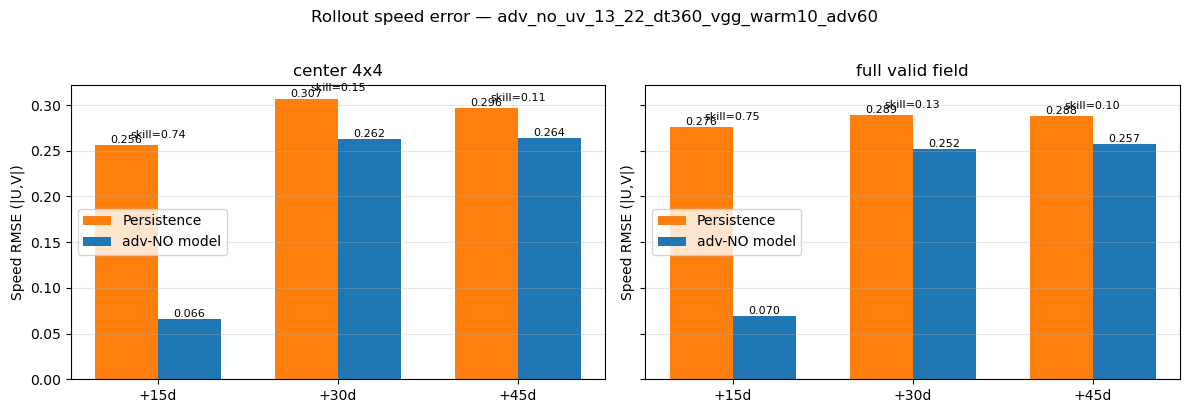

Saved: PNG/adv_no_adv_no_uv_13_22_dt360_vgg_warm10_adv60_speed_rmse_center_and_full.png


In [ ]:
# Bar plots: center 4x4 and full field  
labels = [f"+{d}d" for d in EVAL_HORIZONS]
x = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, persist, model, skill, title in [
    (axes[0], persist_center, model_center, skill_center, f"center {SPEED_PATCH_SIZE}x{SPEED_PATCH_SIZE}"),
    (axes[1], persist_full, model_full, skill_full, "full valid field"),
]:
    ax.bar(x - width / 2, persist, width, label="Persistence", color="#ff7f0e")
    ax.bar(x + width / 2, model, width, label="adv-NO model", color="#1f77b4")
    ax.set_xticks(x, labels)
    ax.set_ylabel("Speed RMSE (|U,V|)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    for i, (p, m, s) in enumerate(zip(persist, model, skill)):
        ax.text(i - width / 2, p, f"{p:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(i + width / 2, m, f"{m:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(i, max(p, m) * 1.02, f"skill={s:.2f}", ha="center", va="bottom", fontsize=8)

fig.suptitle(f"Rollout speed error — {RUN_NAME}", y=1.02)
plt.tight_layout()
out_path = os.path.join(PNG_DIR, f"adv_no_{RUN_NAME}_speed_rmse_center_and_full.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out_path}")


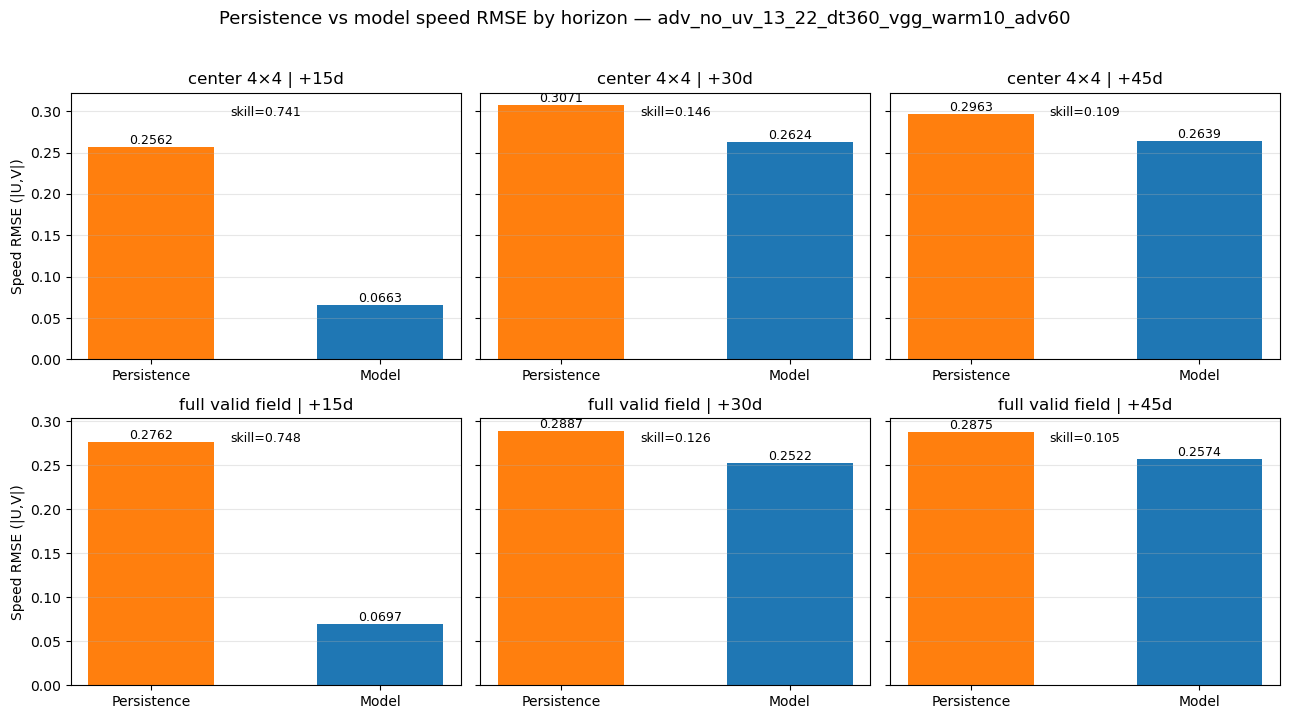

Saved: PNG/adv_no_adv_no_uv_13_22_dt360_vgg_warm10_adv60_speed_rmse_by_horizon_center_and_full(2023).png


In [ ]:
# Per-horizon plots: persistence vs model RMSE (+15d / +30d / +45d)
# Row 0 = center 4×4, row 1 = full valid field; one panel per horizon
width = 0.55

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey="row")
region_rows = [
    (persist_center, model_center, skill_center, f"center {SPEED_PATCH_SIZE}×{SPEED_PATCH_SIZE}"),
    (persist_full, model_full, skill_full, "full valid field"),
]

for row, (persist, model, skill, row_title) in enumerate(region_rows):
    for col, (days, p, m, s) in enumerate(zip(EVAL_HORIZONS, persist, model, skill)):
        ax = axes[row, col]
        bars = ax.bar(["Persistence", "Model"], [p, m], color=["#ff7f0e", "#1f77b4"], width=width)
        ax.set_title(f"{row_title} | +{days}d")
        ax.set_ylabel("Speed RMSE (|U,V|)" if col == 0 else "")
        ax.grid(True, axis="y", alpha=0.3)
        for bar, val in zip(bars, [p, m]):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                val,
                f"{val:.4f}",
                ha="center",
                va="bottom",
                fontsize=9,
            )
        ax.text(0.5, 0.95, f"skill={s:.3f}", ha="center", va="top", fontsize=9, transform=ax.transAxes)

fig.suptitle(f"Persistence vs model speed RMSE by horizon — {RUN_NAME}", y=1.02, fontsize=13)
plt.tight_layout()
out_path = os.path.join(PNG_DIR, f"adv_no_{RUN_NAME}_speed_rmse_by_horizon_center_and_full({EVAL_TAG}).png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out_path}")

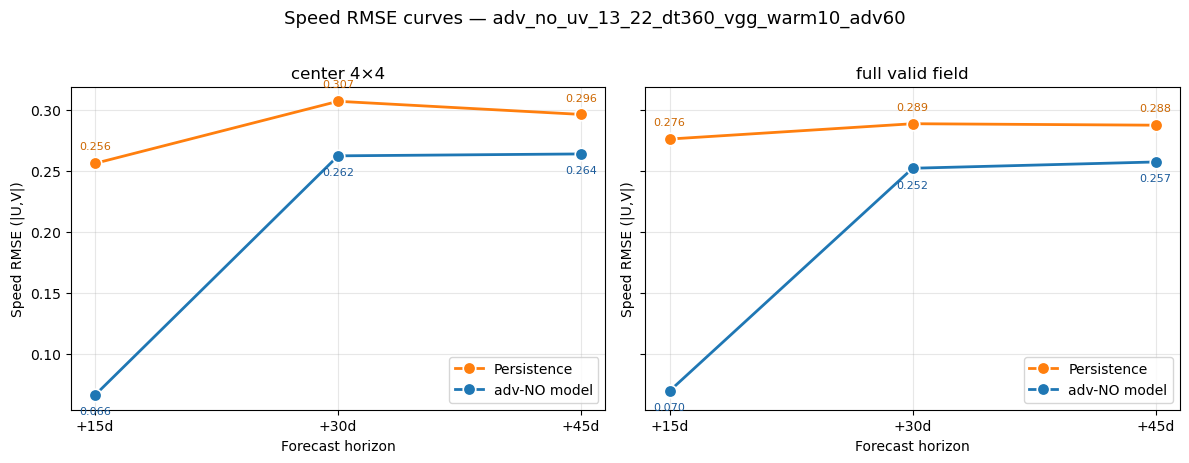

Saved: PNG/adv_no_adv_no_uv_13_22_dt360_vgg_warm10_adv60_speed_rmse_curves_center_and_full(2023).png


In [ ]:
# Line + point curves: persistence vs model RMSE vs horizon (+15d / +30d / +45d)
horizons = np.array(EVAL_HORIZONS, dtype=float)
xtick_labels = [f"+{int(d)}d" for d in horizons]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, persist, model, title in [
    (axes[0], persist_center, model_center, f"center {SPEED_PATCH_SIZE}×{SPEED_PATCH_SIZE}"),
    (axes[1], persist_full, model_full, "full valid field"),
]:
    ax.plot(
        horizons, persist,
        "-o", color="#ff7f0e", linewidth=2, markersize=9,
        markerfacecolor="#ff7f0e", markeredgecolor="white", markeredgewidth=1.2,
        label="Persistence",
    )
    ax.plot(
        horizons, model,
        "-o", color="#1f77b4", linewidth=2, markersize=9,
        markerfacecolor="#1f77b4", markeredgecolor="white", markeredgewidth=1.2,
        label="adv-NO model",
    )
    for d, p, m in zip(horizons, persist, model):
        ax.annotate(f"{p:.3f}", (d, p), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8, color="#cc6600")
        ax.annotate(f"{m:.3f}", (d, m), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#1a5a9a")

    ax.set_xticks(horizons)
    ax.set_xticklabels(xtick_labels)
    ax.set_xlabel("Forecast horizon")
    ax.set_ylabel("Speed RMSE (|U,V|)")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)

fig.suptitle(f"Speed RMSE curves — {RUN_NAME}", y=1.02, fontsize=13)
plt.tight_layout()
out_path = os.path.join(PNG_DIR, f"adv_no_{RUN_NAME}_speed_rmse_curves_center_and_full({EVAL_TAG}).png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out_path}")